This code is used to analyse the cumulative burst energy distirbution.

When comparing telescopes we make sure to only use bursts that fall within the same MJD time frame in order to be able to compare apples to apples. Comparision frame in MJD: 60497 - 60570

In [1]:
#General packages, powerlaw is vital for this analysis
import numpy as np
import numpy.ma as ma
from tqdm import tqdm
import random
import pandas as pd
import powerlaw

#Matplotlib packages
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from matplotlib import rcParams
from matplotlib import transforms

#Scipy packages 
from scipy.optimize import curve_fit
from scipy.stats import chi2
import scipy.optimize as spopt

#Astropy packages
from astropy import units as u
from astropy.cosmology import Planck15 as cosmo

# #Figure settings
# import matplotlib
# matplotlib.rcParams['mathtext.fontset'] = 'custom'
# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [2]:
def pl_dist_pdf(x, x_min, ind):
    """PDF of power law distribution"""
    return (ind - 1) * (x/x_min)**-ind / x_min

In [3]:
def get_rate_errors(bursts, conf_level=0.90):
    low_lim, upp_lim = get_poisson_error(bursts, conf_level=conf_level)
    # if no bursts are detected, get single sided upper limit as rate 
    lim = bursts == 0

    new_conf_level = 1 - ( (1-conf_level)*2 ) # for single sided upper limit 
    _, upp_lim[lim] = get_poisson_error(np.array([0]), conf_level=new_conf_level)
    
    dx_upp = upp_lim - bursts
    dx_low = bursts - low_lim

    return dx_low, dx_upp 

In [4]:
def get_poisson_error(r, conf_level=0.68):
    """
    adapted from Gehrels et al. 1986
    example use:
    rate = np.array([1,2,3,10])
    get_poisson_error(rate, conf_level=0.68) # returns 1-sigma lower and upper limit on the rate
    
    can be used to get the lower and upper limits for burst rate. 
    If bursts_obserrved = 0, it becomes a one sided distrubution, wherein conf_level_onesided = 1 - (1-conf_level)*2 
    """
    low_lim = 0.5 * chi2.ppf((1 - conf_level) / 2, 2 * r)
    low_lim[np.isnan(low_lim)] = 0 
    upp_lim = 0.5 * chi2.ppf((1 + conf_level) / 2, 2 * (r+1))
    upp_lim[np.isnan(upp_lim)] = 0
    
    return low_lim, upp_lim

In [5]:
def nancay(csv_file, mjd_limit=True):
    """
    Function to import the fluences for the NRT sample

    TODO: perhaps add a simple differential distirbution on Fluences?
    """
    
    nancay_df = pd.read_csv(csv_file, on_bad_lines='skip', header=0, sep=';')
    mjds = nancay_df['MJD_at_peak'].values
    print(f"The first burst by NRT was detected on {np.min(mjds):.3f}")
    print(f"The last burst by NRT was detected on {np.max(mjds):.3f}")
    
    if mjd_limit ==True:
        #These dates are the entire campaign for now
        mjd_begin = 60496
        mjd_end = 60602
        nancay_df = nancay_df[nancay_df['MJD_at_peak'].between(mjd_begin, mjd_end)]
    
    fluences = nancay_df['fluence_Jyms'].values

    #Filter on Fluences that have
    zero_fluences = fluences[fluences < 0]
    print(f"The array with Fluences below zero: {zero_fluences}")

    #Fail safe filter on Fluences -- This does nothing in the final csv file
    fluences = fluences[fluences >= 0]

    print(f"There are {len(fluences)} bursts in this sample")
    return fluences

nrt_fluence_mkt = nancay(csv_file="/home/omar/git/frb20240619d-single-dish-analysis/dbs/nrt/nrt_burst_db_v2.csv",\
                                 mjd_limit=False)

The first burst by NRT was detected on 60497.020
The last burst by NRT was detected on 60537.932
The array with Fluences below zero: []
There are 206 bursts in this sample


In [6]:
def fluence_limit(sefd=420, width=1, bw=100, snr=20):
    '''
    sefd in Jy, width in ms, bw in MHz
    '''
    
    fluence_limit = snr * sefd * np.sqrt( (width/1000.) / (2 * bw * 1e6))
    # return things in Jy~ms
    return fluence_limit * 1000

In [7]:
def toa_calulator(df):
    '''
    Return the toa of a burst
    in the case of multiple components of a single burst, take the middle of the burst
    '''
    if df.shape[0] == 1:
        mjd = df.iloc[0]["toa_bary_tdb_inf_freq"]

    elif df.shape[0] > 1:
        mjd_list = df["toa_bary_tdb_inf_freq"].values
        mjd = (mjd_list[0] + mjd_list[-1]) / 2
 
    return mjd

In [8]:
def fluence_looper(df_fluence):
    """
    function to sum over the fluences components of bursts
    returns the burst id and fluences in a pandas df
    
    Input: The burst_csv file with all information, spc/sfxc/scale
    This is needed because we return a df with fluence (spc) and toa (sfxc)
    """

    #the burst names to loop over
    exps = df_fluence['id'].unique()
    #Create a list with the telescope names for easy filtering later on
    exps_tel = [i.split('-')[1] for i in exps]

    #loop over every burst to sum the fluence
    info_list = []
    for exp, telescope in zip(exps, exps_tel):
        
        #Fluence: Making a small temp df for each exp, only taking the spc values
        if telescope != 'st':

            #2bit exception
            if exp == "B08-wb" or exp == "B09-wb":
                fluence_df_exp_temp = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'sfxc')]
            else:
                fluence_df_exp_temp = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'spc')]

            #TOA
            fluence_df_exp_temp_mjd = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'sfxc')]
            toa = toa_calulator(fluence_df_exp_temp_mjd) 
                
        elif telescope == 'st':
            fluence_df_exp_temp = df_fluence[df_fluence['id'] == exp]
            
            #TOA
            toa = toa_calulator(fluence_df_exp_temp) 
            
        #Calculate the total fluence
        fluence = sum(fluence_df_exp_temp['fluence_jyms'].values)
        
        #Since the F0 is the same for all components, take all components
        cent_freq = fluence_df_exp_temp['f0_MHz'].values[0]
                            
        #Add to the list
        info_list.append([fluence, cent_freq, toa])
        
    #Convert the fluence list to array
    info_list_arr = np.asarray(info_list)

    #Convert the info to dataframe
    new_data = {'id': exps, 'fluence': info_list_arr[:,0], 'telescope': exps_tel, 'c_freq':info_list_arr[:,1], 'toa': info_list_arr[:,2]}
    df_new_fluence = pd.DataFrame(data=new_data)

    #add only the index number as a seperate column for potential later use
    df_new_fluence['burst-index'] = df_new_fluence['id'].str.split('-').str[0].str[1:].astype(int)
    
    return df_new_fluence

In [9]:
def load_df(file, band, overlap_wb_st=False, mjd_limit=False):
    """
    Function to load in the burst.csv file and return the Fluences per burst
    
    band: specifiy wether Lband or Pband bursts
    mjd_limit: use the MJD_range or use all bursts in the dataset
    
    notes:
    B84  is missing, since it was determined to not be real after classification
    B130 is actively removed from calculations, since the RFI made it impossible to measure properties
    """

    #load in the main csv file
    fluence_df = pd.read_csv(file, index_col=0)
    
    fluence_df.sort_values(by=['id'])
    ##Wb, On and Tr Fluences
    #Only take the spc fluences
    #df_spc = fluence_df[fluence_df['src'] == 'spc']
    df_combined = fluence_looper(fluence_df)    
    df_combined.sort_values(by=['id'])
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        df_combined = df_combined[df_combined['toa'].between(mjd_begin, mjd_end)]
                
    #Resort and reset the df
    df_combined = df_combined.sort_values(by=['burst-index'])
    df_combined = df_combined.reset_index(drop=True)
    
    #display(df_combined)
    return df_combined

fluence_df = load_df("../dbs/hyperflash_mkt_burst_db.csv", band="L", mjd_limit=False)
display(fluence_df)

,id,fluence,telescope,c_freq,toa,burst-index
0,B01-wb,771.730607,wb,1271.000000,60511.994427,1
1,B02-st,100.749183,st,1381.464844,60526.896118,2
2,B02-wb,154.559939,wb,1271.000000,60526.896127,2
3,B03-st,70.264176,st,1381.464844,60530.882722,3
4,B04-st,171.984368,st,1381.464844,60535.945584,4
5,B05-st,30.583585,st,1381.464844,60536.884172,5
6,B05-wb,102.917272,wb,1271.000000,60536.884182,5
7,B06-wb,104.169794,wb,1271.000000,60537.888455,6
8,B07-st,27.111312,st,1381.464844,60553.898090,7
9,B07-wb,41.323009,wb,1271.000000,60553.898099,7


In [10]:
def fluences_arrays(df_fluences, telescope):
    "return Fluences arrays from different activity windows"

    #Westerbork
    fluences = df_fluences[df_fluences['telescope'] == telescope]
    fluences_arr = fluences['fluence'].values
    fluences_arr[::-1].sort()

    print(f'{telescope} : {len(fluences_arr)}')
    return fluences_arr

fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')

wb : 9
st : 5


Calculating best minimal value for power law fit
Turning point: 2.326666958793849 jy ms
breakpoint of the double powerlaw: 28.26 jy ms


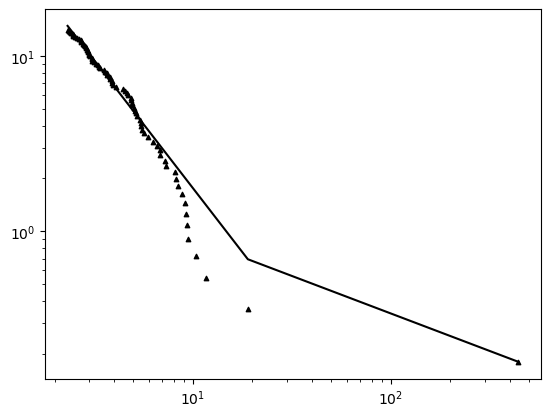

Due to the number of datapoints this first estimate can not be trusted


28.260011496431584

In [11]:
def func_broken_powerlaw(x, scale=1, gamma1=1, gamma2=1, ebreak=1):

    return np.piecewise(x, 
                        [x < ebreak, x >= ebreak],
                        [lambda x: scale * (x/ebreak)**gamma1, lambda x: scale * (x/ebreak)**gamma2])

def breakpoint_nancay(fluences, obs_h):

    ############
    #Double Powerlaw
    ############
    
    #Apply a broken powerlaw fit to the data to find the breakpoint
    #Next we will seperately fit 2 powerlaws to the data in order to take into account error propagation
    #This seems dirty, and it is, but that is what you get 
    
    #Energy is sorted from high-low
    
    energies_arr = fluences
    energies_arr.sort()
    
    pw_results = powerlaw.Fit(energies_arr)
    print("Turning point:", pw_results.xmin, "jy ms")

    energies_fit_p = energies_arr[energies_arr>=pw_results.xmin]
    y_points_fit = np.arange(1, len(energies_fit_p)+1, 1) / obs_h
    popt2, pcov2 = curve_fit(func_broken_powerlaw, np.sort(energies_fit_p), np.flip(y_points_fit),
                           p0 = np.asarray([0.2, -1.8,-0.4,20]), maxfev=50000)

    breakpoint = popt2[-1]
    
    print(f"breakpoint of the double powerlaw: {breakpoint:.2f} jy ms")

    ### Simple diagnostic tool
    # I used this plotting code snippet to confirm if the fit went alright.
    # 25-Apr-24
    plt.figure()
    plt.plot(energies_fit_p,func_broken_powerlaw(energies_fit_p,*popt2),color='black',lw=1.5)
    plt.scatter(np.sort(energies_fit_p), np.flip(y_points_fit), color='black', marker="^", s=10)
    plt.xscale('log')
    plt.yscale('log')
    plt.show()
    print("Due to the number of datapoints this first estimate can not be trusted")
    ####

    return breakpoint

breakpoint_nancay(fluences=nrt_fluence_mkt, obs_h=5.54)

In [12]:
# Function to calculate energy per Hz at a given redshift (z)
def isotropic_energies(fluences_jy_ms, dist_mpc, z):
    
    # Convert fluence from Jy·ms to Jy·s
    fluence_jys = fluences_jy_ms * 1e-3  # Jy·s
    
    # Convert the distance from megaparsec to cm
    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value

    #mpc to cm
    distance_lum_cm = megap_cm*dist_mpc

    #Redshift correction, see Macquart and Eckers for the function
    red_cor = 1 / (1 + z)**2

    # calculate energy per Hz
    energy_specific = fluence_jys * 4*np.pi*(distance_lum_cm**2) * 1e-23 * red_cor
    
    return energy_specific

In [13]:
def energy_to_fluence(energies, distance=362.4,z=0.0771):
    """Convert isotropic energies to fluences"""
    "Needed for the inverse calculation for a secondary axis"
    # Convert distance from Mpc to cm
    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value
    distance_lum_cm = megap_cm * distance

    # Apply redshift correction
    red_cor = 1 / (1 + z)**2

    # Calculate fluence in Jy ms
    fluence_jys = energies / (4 * np.pi * (distance_lum_cm**2) * 1e-23 * red_cor)
    fluences = fluence_jys * 1e3  # Convert from Jy s to Jy ms
    return fluences

In [14]:
def func_powerlaw(x, scale=1, gamma=1):
    return x**gamma * scale

In [15]:
def slope_est(energies_array, conf_level=1):
    """
    Function to do a first order estimate of the slope and error
    method used in papers from Hewitt, Nimmo and Kirsten
    
    essentially eq 3 from this paper:
    link: https://ui.adsabs.harvard.edu/abs/2019MNRAS.483.1342J/abstract
    """

    energies_array.sort()
    M=len(energies_array)
    si=np.array(energies_array)/energies_array[0]

    corrfact=(M-1)/M
    a_star=corrfact*1/( (-1/M) * np.sum(np.log(si)) )
    err= M*a_star / ( (M-1)*(M-2)**0.5 )
    
    if conf_level == 2:
        err = err * 2

    return a_star,err

In [16]:
def gamma_slopes(energies_arr, conf_level=1):
    """
    Iterativly refit a best slope guess for a powerlaw distribution by removing points
    The errors at 2-sigma, since we multiply by 2 in the error
    """
    
    energies_arr.sort()
    total_gamma = []
    energy_threshold = []
    error_ar = []

    for j in range(1,len(energies_arr)-1):
        alpha = (1/( -1/len(energies_arr[energies_arr>energies_arr[j]]) * \
                    np.sum(np.log(energies_arr[energies_arr>energies_arr[j]] / energies_arr[j]))))
        M = len(energies_arr[energies_arr>energies_arr[j]])
        
        alpha = ((M-1)/M) * alpha
        total_gamma.append(alpha)
        energy_threshold.append(energies_arr[j])

        if M > 2:
        #We multiply by 2 to convert the 1-sigma error to 2 sigma errors
            error = M * alpha / ((M-1)*(M-2)**0.5) 
            
            if conf_level == 2:
                error = error * 2
        
            error_ar.append(error)
            
    return total_gamma, energy_threshold, error_ar

In [17]:
def power_law_fit(energies, observed_time, scale=1, limit=(1, 1),
                  limit_b=False, fit=True, ignore_turnover=False,
                  time_is_weights=False, ex_max=None):
    "Function to return the fitted powerlaw to the datapoints"

    energies.sort()
    if fit:
        #Determine the turning point in the powerlaw with the Powerlaw module -- From the powerlaw paper:
        #The search for the optimal xmin can also be restricted to a range, given as a tuple or list:
        #if xmin is two values, powerlaw will search for a turnover points between these values
        if not limit_b:
            pw_results = powerlaw.Fit(energies)
            print(f"Turning point: {pw_results.xmin:.2f} energy units")
        else:
            pw_results = powerlaw.Fit(energies,  xmin=(limit[0],limit[1]))#, xmax=limit[1])
            print(f"No limit_b, Turning point: {pw_results.xmin:.2f} energy units")
            
        if ignore_turnover:
            pw_results.xmin = limit[0]

        print(f"pw xmin: {pw_results.xmin:.2f}, xmax: {pw_results.xmax}")

        #Values that will be included in the fit
        energies_fit = energies[energies>=pw_results.xmin]

        #Values that are excluded in the fit
        energies_ex = energies[energies<pw_results.xmin]

        if not time_is_weights:
            #The burst rate, devide by the observed_time to get a rate per hours
            #ypoints for the fitted data
            y_points_fit = np.arange(1, len(energies_fit)+1, 1) / observed_time

            #ypoints for the not fitted data; scaled
            y_points_ex = np.arange(len(energies_fit)+1,
                                    len(energies_fit)+len(energies_ex)+1, 1) / observed_time
        else:
            y_points_fit = observed_time
            y_points_ex = []
            
        ###
        #Curve_fit for the slope estimate; this is just a first guess
        a_star, a_err = slope_est(energies)
        print(f"estimate using the a_star method: {a_star:.3f} {a_err:.3f}")
        ###

        # Functionality to exclude points in the high energy tail
        if ex_max is not None:
            print(f"ex_max = {ex_max}")
            print(f"Excluding max_energy; cutting off the last {ex_max} points")
        
            # Make copies of the original arrays before modifying them
            original_energies_fit = energies_fit.copy()
            original_y_points_fit = y_points_fit.copy()
        
            # Determine how many points to include and skip
            skip_burst = ex_max
            included = len(original_energies_fit) - skip_burst
        
            # Extract the excluded (high-energy) tail points
            ex_energies_high = original_energies_fit[included:]
            ex_y_points_high = original_y_points_fit[:skip_burst]
            print(f"Excluded coordinates: {ex_energies_high}, {ex_y_points_high}")

            #Making the expoints coordinates into 1 item to be returned
            ex_points_high = np.array([ex_energies_high, ex_y_points_high])
            
            # Truncate arrays to keep only the included data for fitting
            energies_fit = original_energies_fit[:included]
            y_points_fit = original_y_points_fit[skip_burst:]
            print(f"New FIT length: {len(energies_fit)}")

        else:
            ex_points_high = None
            
        #apply curve_fit to do the fit
        popt, pcov = curve_fit(func_powerlaw, energies_fit, np.flip(y_points_fit),
                               p0 = np.asarray([scale, a_star]), maxfev=50000)

        #flip x and y to use the x-error -- the multiply 0.2 is the 20% error on the energies
        popt_flip, pcov_flip = curve_fit(func_powerlaw, np.flip(y_points_fit),energies_fit,
                                         p0=[popt[0]**(1./-popt[1]), 1./popt[1]],
                                         sigma=np.asarray(energies_fit*0.2),\
                                         absolute_sigma=True)

        #Calculate the popt values in the xy frame, use the errors on the fit
        popt_back=[popt_flip[0]**(1./-popt_flip[1]), 1./popt_flip[1]]
        sol2 = [popt_back, pcov_flip]
        #print(sol2)

        sol2_err = np.sqrt(np.diag(sol2[1]))
        xx = np.linspace(np.min(energies_fit),np.max(energies_fit),500)
        p_y = func_powerlaw(xx, *sol2[0])

        ##Bootstrapping -- getting the variance on the error
        subset_int = int(len(energies_fit) * 0.9)
        print(f"Bootstrapping, only using {subset_int} points out of {len(energies_fit)} points")

        N=1000
        alpha_list = []
        for trial in tqdm(range(N)):

            #subset_list = random.sample(list(energies_fit), k = subset_int)

            #Get a random sample of 90% from the fitted energies
            ss_energie, ss_ypoint = zip(*random.sample(list(zip(energies_fit, y_points_fit)),
                                                       k=subset_int))

            #Sort them again from big to small
            ss_energie_1, ss_ypoint_1 = zip(*sorted(zip(ss_energie, ss_ypoint)))
            popt_bs_yx, pcov_bs_yx=curve_fit(func_powerlaw,np.flip(ss_ypoint_1),ss_energie_1,
                                             p0=[popt[0]**(1./-popt[1]),1./popt[1]],
                                             sigma=np.asarray(ss_energie_1)*0.2,absolute_sigma=True)

            #Covert back to values, bootstramp reversed
            popt_bs_r=[popt_bs_yx[0]**(1./-popt_bs_yx[1]),1./popt_bs_yx[1]]

            #Append the value for the slope the list
            alpha_list.append(popt_bs_r[1])

        #Calculate the boot_alpha
        boot_alpha = np.std(alpha_list)
        print(f"boot_alpha: {boot_alpha:.2f}")

        return energies_fit, y_points_fit, energies_ex, y_points_ex, \
            sol2, sol2_err, pw_results.xmin, boot_alpha, ex_points_high
    else:
        if not time_is_weights:
            y_points = np.arange(1, len(energies)+1, 1) / observed_time
        else:
            y_points = observed_time
            
        return energies, y_points

############# Fitting: Westerbork #############
Calculating best minimal value for power law fit
No limit_b, Turning point: 41.32 energy units
pw xmin: 41.32, xmax: None
estimate using the a_star method: -0.365 -0.155
Bootstrapping, only using 7 points out of 8 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2765.88it/s]


boot_alpha: 0.14
############# Fitting: Stockert #############
Calculating best minimal value for power law fit
No limit_b, Turning point: 27.11 energy units
pw xmin: 27.11, xmax: None
estimate using the a_star method: -0.945 -0.682
Bootstrapping, only using 4 points out of 5 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2449.59it/s]


boot_alpha: 0.15
############# Fitting: NRT #############
Calculating best minimal value for power law fit
No limit_b, Turning point: 2.33 energy units
pw xmin: 2.33, xmax: None
estimate using the a_star method: -0.570 -0.040
ex_max = 1
Excluding max_energy; cutting off the last 1 points
Excluded coordinates: [441.63950512], [0.18050542]
New FIT length: 77
Bootstrapping, only using 69 points out of 77 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2229.72it/s]


boot_alpha: 0.09
Plot the high energy excluded points


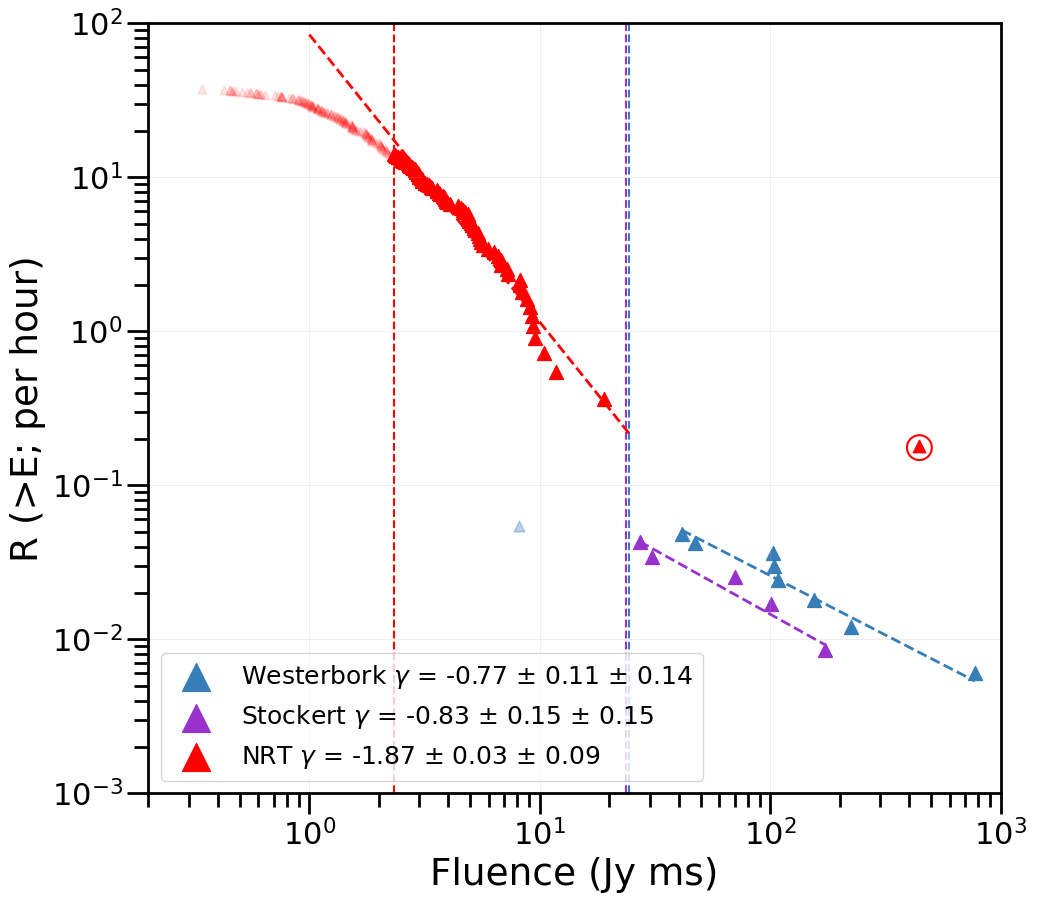

In [37]:
def cumulative_energy_dist(save_bool=False):
    '''
    Function to plot the cumulative energy distribution
    mjd range: mjd_begin = 60497 mjd_end = 60570
    The observing hours are calculated using the hours_calc script.
    
    Telescopes used: NRT / Stockert / Westerbork
    
    Output: Cumulative distribution
    '''

    # energies_array_stk = isotropic_energies(fluences_stk_arr)
    # energies_array_wb = isotropic_energies(fluences_wb_arr) 
    #energies_array_nc = isotropic_energies(fluences_nc_arr)  
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    #energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=90, snr=15)
    #energie_threshold_stk = isotropic_energies([f_limit_stk]
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=400, width=3, snr=15)
    # energie_threshold_nc = isotropic_energies([f_limit_nc])
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_stk_arr, nrt_fluence_mkt]
    obs_hours = [166.12, 117.6, 5.54]
    thresholds = [f_limit_wb, f_limit_stk, f_limit_nc]
    dish = ['Westerbork', "Stockert", "NRT"]
    color = ['#377eb8', 'darkorchid', 'red']
    limit = [50, 50, 15]
    
    #   Figure
    #plt.figure(figsize=(12,10))
    f, ax = plt.subplots(1, figsize=(11,10))
    
    #Dict that will be returned at the end of the function
    sols_dict = {}
    tresh = {}
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"############# Fitting: {dish} #############")
        
        #Energy is sorted from high-low
        energies_arr = fluences_arr
        
        if dish == "NRT":
            ex_max_num = 1
        else:
            ex_max_num = None
            
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha, ex_points_high = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10, \
                              limit=(energie_threshold, limit),limit_b=True,ex_max=ex_max_num)
        
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, s=100,\
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")
        
        if dish == "NRT":
            plt.axvline(turning_point, color=color, linestyle='--')

        # #Get the poissonian count rate errors on the points
        # low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
        # upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
        # plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
        #              yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
        #              alpha = 0.8, color =color,zorder =0,capsize=0, fmt='None')
        

        if dish != "NRT":
            plt.axvline(energie_threshold, color=color, linestyle='--')

        if  dish == "NRT":
            #plot_range = np.logspace(np.log10(1), np.log10(energies_fit[-1]), 50)
            plot_range = np.logspace(np.log10(1), np.log10(25), 50)
            energies_fit = plot_range
            alpha_plot = 0.10
            marker_size = 40
            
        if dish == "Westerbork" or dish == "Stockert":
            plot_range = np.logspace(np.log10(energies_fit[0]), np.log10(energies_fit[-1]), 50)
            energies_fit = plot_range
            alpha_plot = 0.35
            marker_size = 60

        #Plotting the powerlaw
        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=2.0,ls='dashed')

        #Plotting the points that were excluded from the fit (lower energies)
        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=alpha_plot, s=marker_size)

        #To plot the largest energy values that were excluded from the plot using the ex_high function
        if ex_max_num != None:
            print("Plot the high energy excluded points")
            alpha_plot_large = 1.0
            marker_size_large = 80
            ex_energies_high = ex_points_high[0]
            ex_y_points_high = ex_points_high[1]
            plt.scatter(np.sort(ex_energies_high), np.flip(ex_y_points_high), color=color, marker="^", \
                        alpha=alpha_plot_large, s=marker_size_large)

            #This is literally the most ugly thing I have ever done.
            #The circle drawn around the triangle is not centered, so I did it manually. 
            #This only works for a single point; god speed
            ex_energies_high = ex_energies_high + 2
            ex_y_points_high = ex_y_points_high -0.005
            
            # Circles around points using scatter
            plt.scatter(np.sort(ex_energies_high), np.flip(ex_y_points_high),
                        s=marker_size_large * 4, facecolors='none', edgecolors=color, linewidths=1.5)
        
        #sols_dict[color] = sol2
        #tresh[color] = energie_threshold

        #print(f"sols for fit: {sol2}")

    # def fluence_to_energy(fluence):
    #     return isotropic_energies([fluence])[0]

    # def energy_to_fluence_single(energy):
    #     return energy_to_fluence([energy])[0]
        
    # # Secondary X-Axis
    # secax = ax.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    #secax.
    #secax.tick_params(axis='x', labelsize=22, pad=-2.5)

    for ax in [ax]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
                
            ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)


    # Add grid to the main axis
    plt.grid(which="major", alpha=0.2)  # Grid for main axis
    
    plt.ylabel("R (>E; per hour)", fontsize=27)
    plt.xlabel("Fluence (Jy ms)", fontsize=27)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.001,100)
    plt.xlim(0.2,1000)
    
    leg = plt.legend(loc='lower left', markerscale=2, fontsize=18)    
    for lh in leg.legend_handles: 
        lh.set_alpha(1)

    if save_bool:
        save_name = "cumulative_burst_rate_v3"
        plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=300, bbox_inches='tight')
        plt.savefig(f"../plots/{save_name}.png", facecolor='white', transparent=False, \
                    format = 'png',bbox_inches='tight', dpi=300)
    plt.show()

    return 

cumulative_energy_dist(save_bool=True)